# **CVC-ClinicDB Dataset**

In [2]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [3]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "AttentionUNet",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = attention_unet_small(in_channels=3, out_channels=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-07 20:06:12 | INFO | AttentionUNet_model_CVC_ClinicDB_20250907_200612 | Logging to model_comparisons/logs/AttentionUNet_model_CVC_ClinicDB_20250907_200612.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-07 20:06:12 | INFO | AttentionUNet_model_CVC_ClinicDB_20250907_200612 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/lk9wyap0
100%|██████████| 8/8 [00:01<00:00,  7.48it/s]
2025-09-07 20:06:21 | INFO | AttentionUNet_model_CVC_ClinicDB_20250907_200612 | Epoch 001/100 | Train: 1.301884 | Val: 1.245990 | LR: 0.000100 | 8.44s | Val Dice: 0.3523 IoU: 0.2384 F1: 0.4093
2025-09-07 20:06:21 | INFO | AttentionUNet_model_CVC_ClinicDB_20250907_200612 | Saved best: model_comparisons/models/best_AttentionUNet_model_CVC_ClinicDB_20250907_200612.pth (val=1.245990)
100%|██████████| 8/8 [00:00<00:00, 10.59it/s]
2025-09-07 20:06:29 | INFO | AttentionUNet_model_CVC_ClinicDB_20250907_200612 | Epoch 002/100 | Train: 1.151169 | Val: 1.133009 | LR: 0.000100 | 7.45s | Val Dice: 0.4263 IoU: 0.3098 F1: 0.4877
2025-09-07 20:06:29 | INFO | AttentionUNet_model_CVC_ClinicDB_20250907_200612 | Saved best: model_comparisons/models/best_AttentionUNet_model_CVC_ClinicDB_20250907_200612.pth (

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▃▂▃▁▄▄▅▇▆▅▅▇▄▇▄▇▇▅▆▆▂▅▇▃▅▅▆▄▆█▃▇▆▆▅▇▇▅▆▅
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▆▆█▅▅▂▅▂▁▃▂▄▁▅▁▄▂▂▄▃▃▂▆▄▂▅▂▄▂▂▁▃▂▂▁▃▂▃▃▃
epoch_seconds,█▂▁▃▄▂▂▃▂▃▃▃▃▂▂▂▃▂▂▂▄▂▃▂▂▃▂▃▂▂▂▄▂▂▃▄▃▃▃▃
lr,█████████████████████████████████▃▃▃▃▃▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▃▃▄▄▅▆▆▆▇▇▇▇▇▇▇▇▇▇█▇███████████▇███████
train/f1,▁▂▃▃▅▆▆▆▇▇▇▇▇▇▇██▇█████████████▇████████
train/iou,▁▂▂▃▄▅▅▅▆▆▆▇▇▇▇▇▇▇▇███████████▇▇████████
+11,...


{'best_val_loss': 0.2697438430041075,
 'epochs_ran': 61,
 'best_model_path': 'model_comparisons/models/best_AttentionUNet_model_CVC_ClinicDB_20250907_200612.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_AttentionUNet_CVC_ClinicDB_20250907_200612.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/lk9wyap0',
 'log_path': 'model_comparisons/logs/AttentionUNet_model_CVC_ClinicDB_20250907_200612.log'}

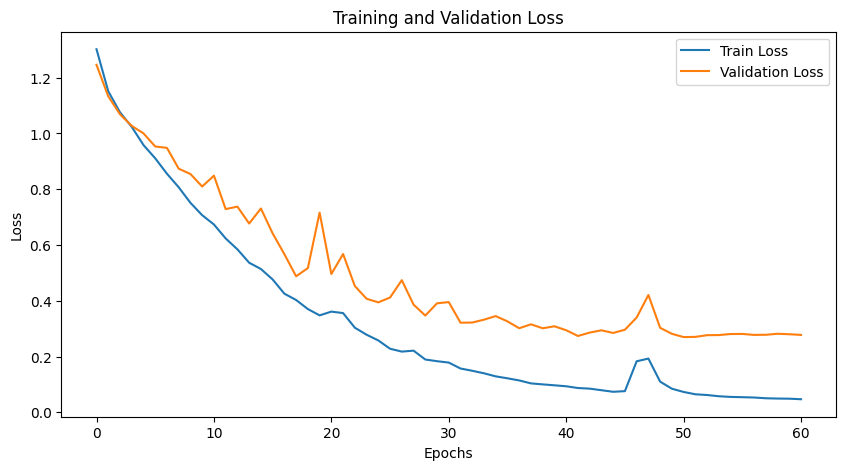

In [7]:
trainer.plot_losses()

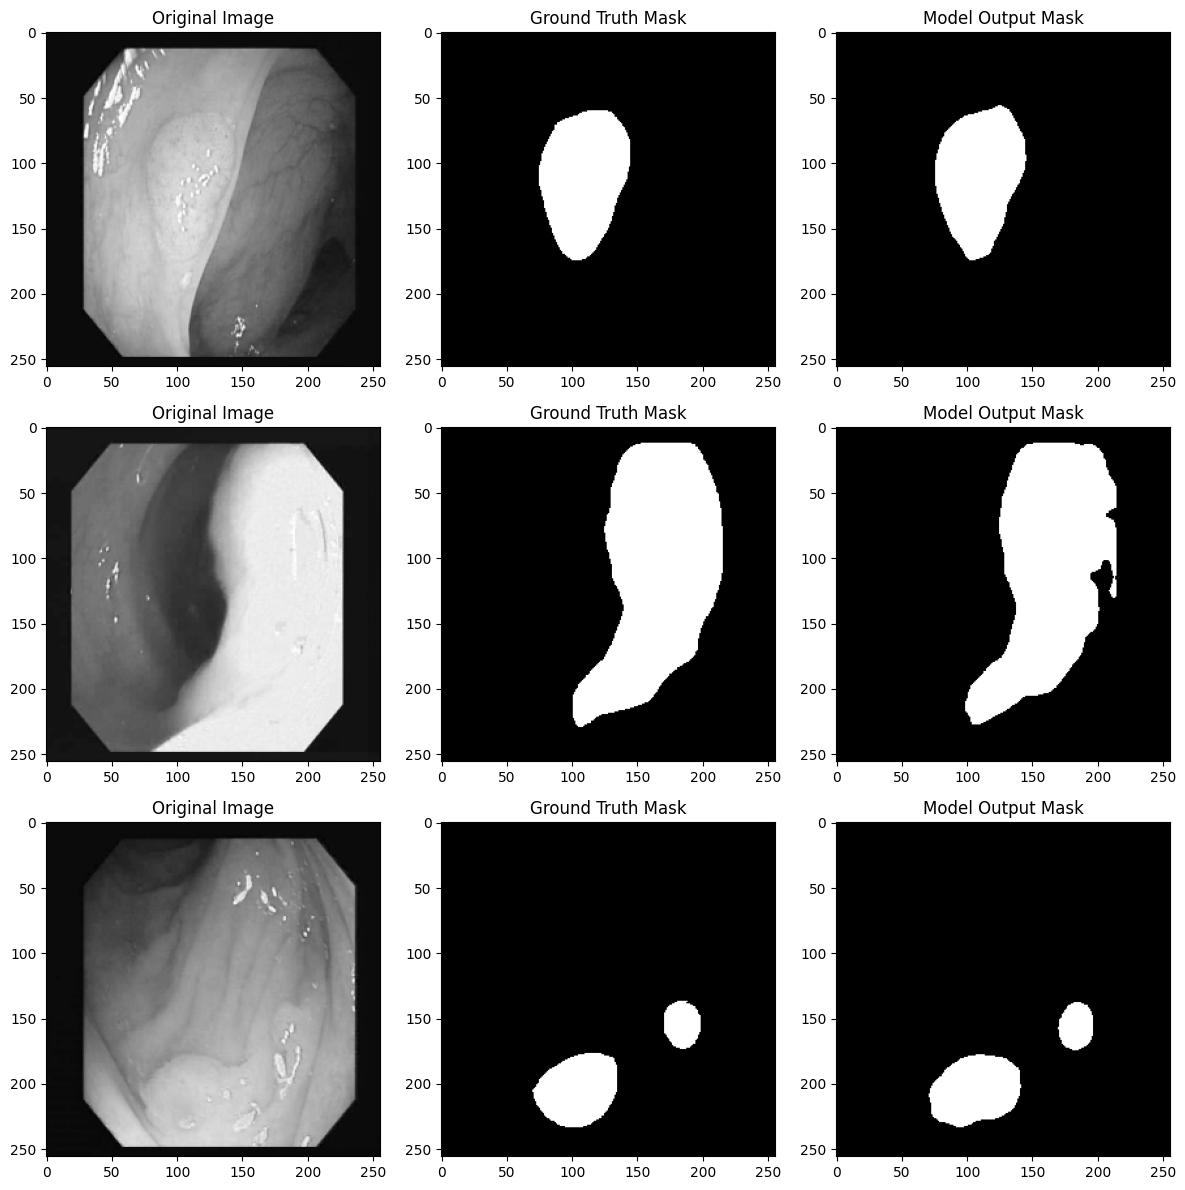

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:00<00:00, 10.26it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.2775
Average Dice Score                 : 0.8292
Average Hausdorff Distance         : 30.2299
Average IoU                        : 0.7599
Precision                          : 0.9544
Recall                             : 0.7875
F1 Score                           : 0.8629
IoU (batch avg)                    : 0.7467
Dice (batch avg)                   : 0.8473
Total Parameters                   : 7,854,717
Trainable Parameters               : 7,854,717
Average Inference Time (seconds)   : 0.019812
FPS (Frames Per Second)            : 50.47
FLOPs                              : 14,032,261,120.0
GFLOPs                             : 14.0323

Results saved to: model_comparisons/evaluation_results/AttentionUNet_model_CVC-ClinicDB_evaluation_results_20250907_200612.csv
Validation results saved to model_comparisons/evaluation_results/AttentionUNet_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.2775406762957573,
 'avg_dice_score': 0.8291814883976121,
 'avg_hd_score': 30.22985419534868,
 'avg_iou': 0.7598961804317997,
 'precision': 0.9543795051018816,
 'recall': 0.7874816550374624,
 'f1': 0.8629348531444855,
 'iou_batch_avg': 0.7467486187815666,
 'dice_batch_avg': 0.8473455235362053,
 'total_params': 7854717,
 'trainable_params': 7854717,
 'avg_inference_time': 0.019812350273132325,
 'fps': 50.473567558317775,
 'flops': 14032261120.0,
 'gflops': 14.03226112}

# **Kvasir-SEG dataset**

In [10]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


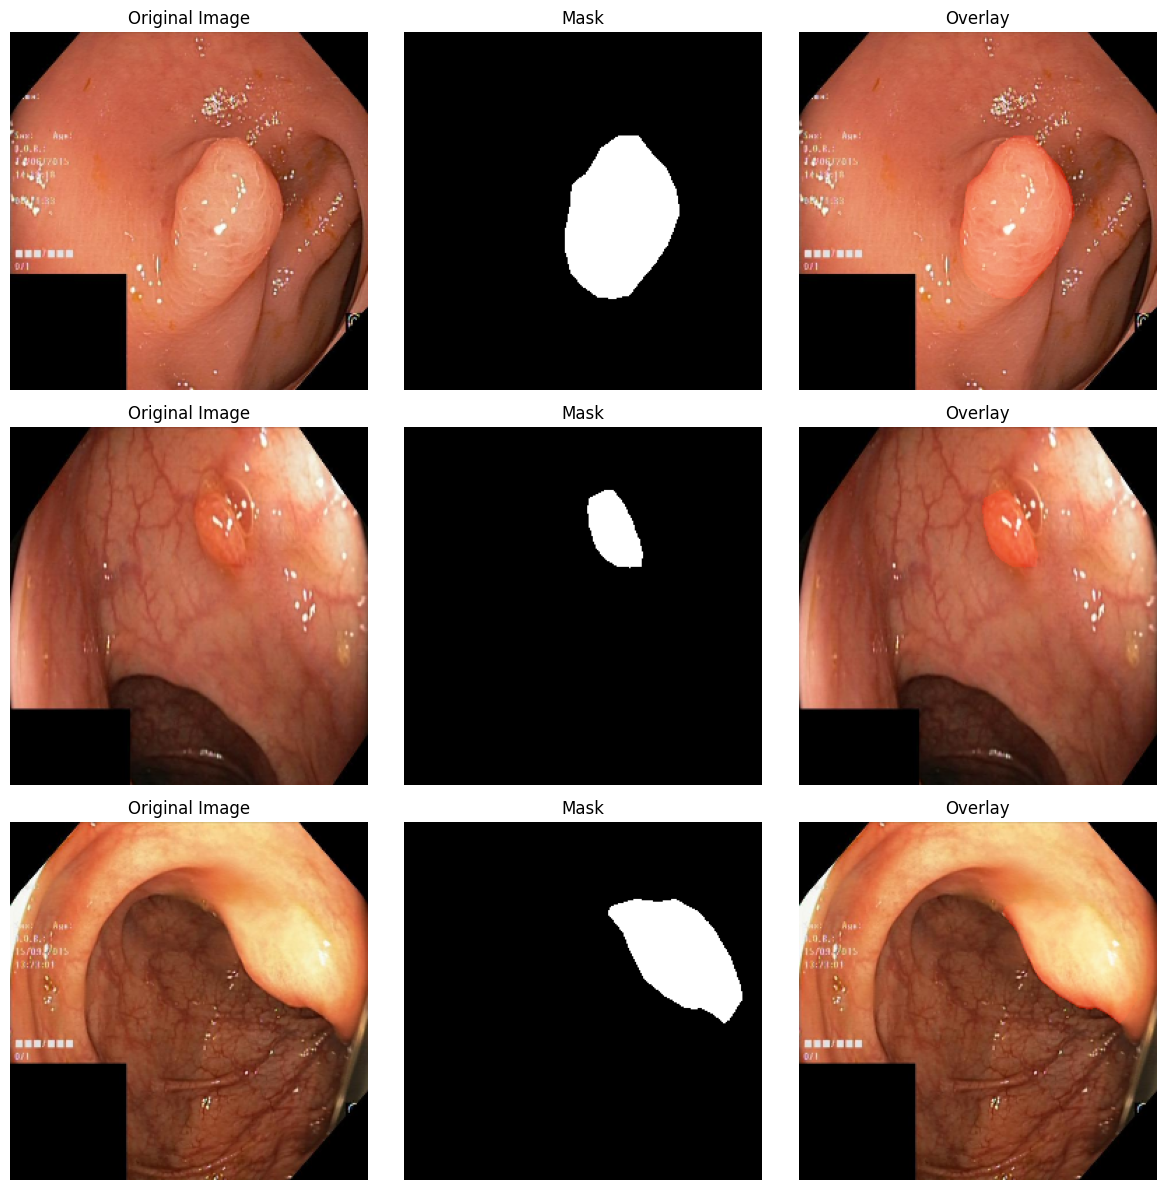

In [11]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

dataset.visualize_samples()

# UNet Kvasir training config

In [12]:
cfg = TrainConfig(
    # --- General ---
    model_name = "AttentionUNet",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-4,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [13]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [14]:
model = attention_unet_small(in_channels=3, out_channels=1)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


2025-09-07 20:14:28 | INFO | AttentionUNet_model_Kvasir_SEG_20250907_201428 | Logging to model_comparisons/logs/AttentionUNet_model_Kvasir_SEG_20250907_201428.log


2025-09-07 20:14:29 | INFO | AttentionUNet_model_Kvasir_SEG_20250907_201428 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/4r82rpmz
100%|██████████| 13/13 [00:02<00:00,  6.34it/s]
2025-09-07 20:14:42 | INFO | AttentionUNet_model_Kvasir_SEG_20250907_201428 | Epoch 001/100 | Train: 1.182734 | Val: 1.040472 | LR: 0.000100 | 12.95s | Val Dice: 0.5478 IoU: 0.4102 F1: 0.5877
2025-09-07 20:14:42 | INFO | AttentionUNet_model_Kvasir_SEG_20250907_201428 | Saved best: model_comparisons/models/best_AttentionUNet_model_Kvasir_SEG_20250907_201428.pth (val=1.040472)
100%|██████████| 13/13 [00:03<00:00,  3.93it/s]
2025-09-07 20:14:56 | INFO | AttentionUNet_model_Kvasir_SEG_20250907_201428 | Epoch 002/100 | Train: 1.025836 | Val: 0.969652 | LR: 0.000100 | 13.64s | Val Dice: 0.5944 IoU: 0.4656 F1: 0.6268
2025-09-07 20:14:56 | INFO | AttentionUNet_model_Kvasir_SEG_20250907_201428 | Saved best: model_comparisons/models/best_AttentionUNet_model_Kvasir_SEG_20250907_201428.pth (val=0.96

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▁▅▇▆▇▇▆▇▇█▇█▇▆▇▆▇▆▅▆▅▇▆▄▆▆▆▄▅▆▅▅▆▅▇▄▆▅▄▅
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,█▄▂▃▂▂▃▂▂▁▂▁▂▂▂▃▂▃▄▃▃▂▃▅▃▃▃▅▄▃▄▃▃▄▂▅▃▄▅▄
epoch_seconds,▆█▇▄▆▆▄▃▃▆▅▄▂▆▁▄▄▂▇▅▄▅▅▂▃▅▄▄▅▆▄▅▅▆▃▆▃▄▅▅
lr,████████████████████████████████████▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇█████████████████
train/f1,▁▂▃▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇█████████████████
train/iou,▁▂▂▃▃▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇███████████████
+11,...


{'best_val_loss': 0.41524771658273846,
 'epochs_ran': 41,
 'best_model_path': 'model_comparisons/models/best_AttentionUNet_model_Kvasir_SEG_20250907_201428.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_AttentionUNet_Kvasir_SEG_20250907_201428.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/4r82rpmz',
 'log_path': 'model_comparisons/logs/AttentionUNet_model_Kvasir_SEG_20250907_201428.log'}

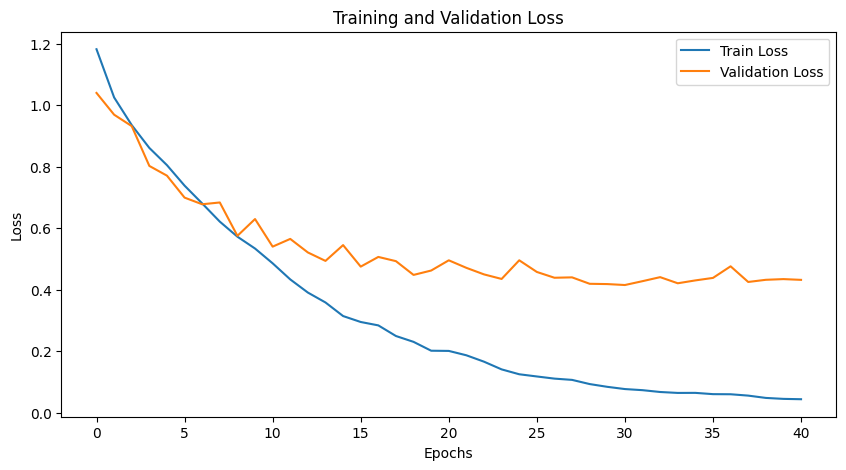

In [15]:
trainer.plot_losses()

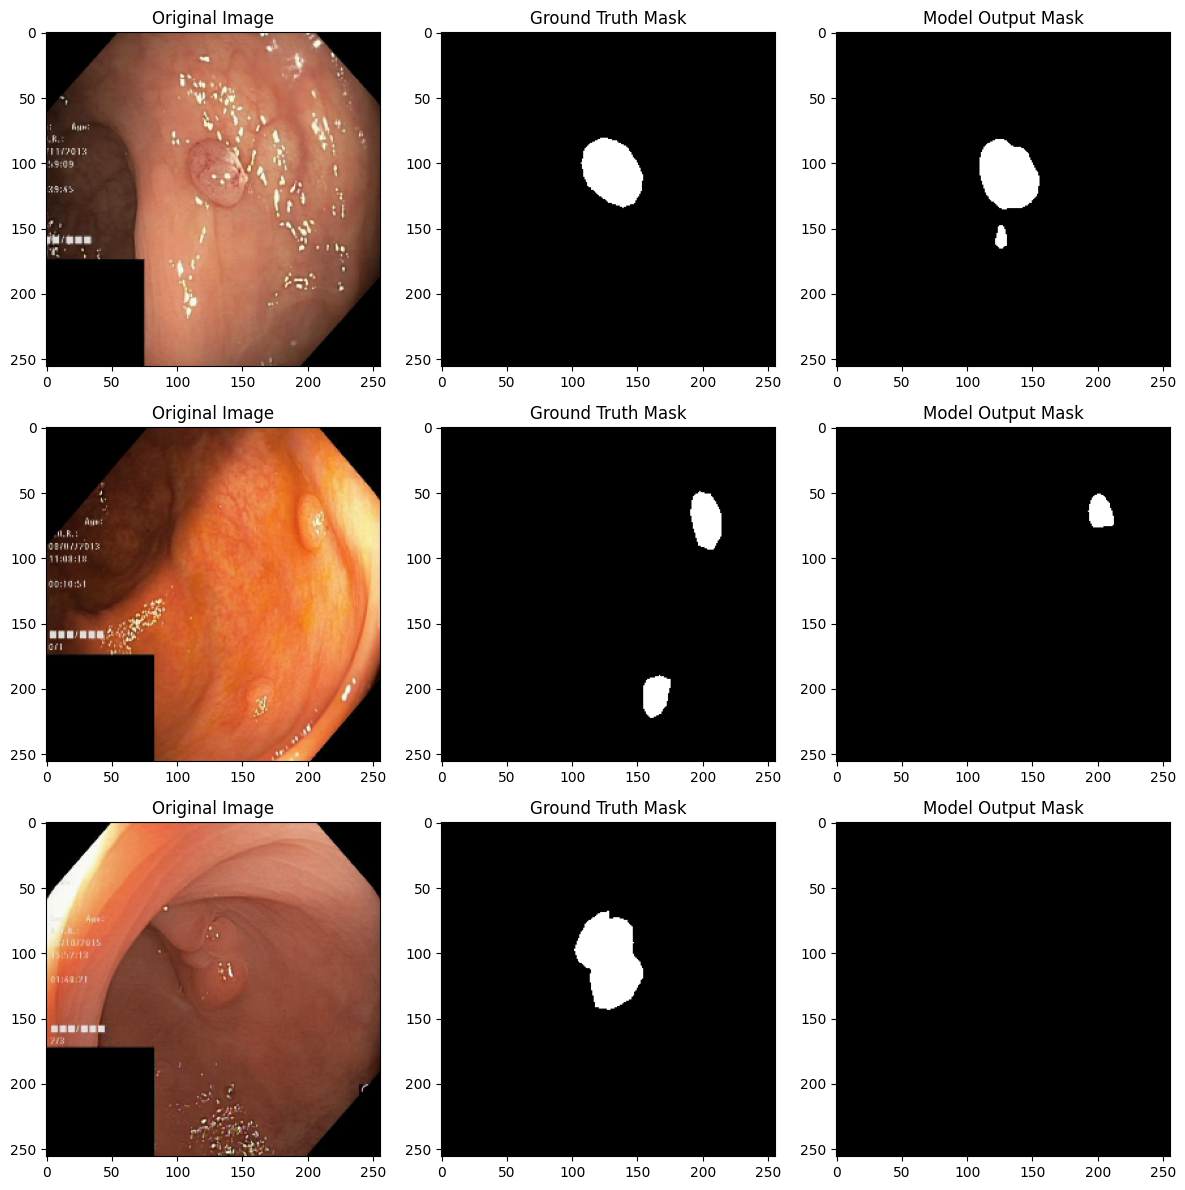

In [16]:
trainer.visualize_output_samples()

In [17]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:02<00:00,  5.58it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4320
Average Dice Score                 : 0.7913
Average Hausdorff Distance         : inf
Average IoU                        : 0.7061
Precision                          : 0.9082
Recall                             : 0.7292
F1 Score                           : 0.8089
IoU (batch avg)                    : 0.6977
Dice (batch avg)                   : 0.8134
Total Parameters                   : 7,854,717
Trainable Parameters               : 7,854,717
Average Inference Time (seconds)   : 0.019888
FPS (Frames Per Second)            : 50.28
FLOPs                              : 14,032,261,120.0
GFLOPs                             : 14.0323

Results saved to: model_comparisons/evaluation_results/AttentionUNet_model_Kvasir-SEG_evaluation_results_20250907_201428.csv
Validation results saved to model_comparisons/evaluation_results/AttentionUNet_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.4320486910068072,
 'avg_dice_score': 0.7913334007575296,
 'avg_hd_score': inf,
 'avg_iou': 0.7061200091629409,
 'precision': 0.9082281098886223,
 'recall': 0.7291674842791979,
 'f1': 0.808907033093265,
 'iou_batch_avg': 0.6976926922798157,
 'dice_batch_avg': 0.8133789667716393,
 'total_params': 7854717,
 'trainable_params': 7854717,
 'avg_inference_time': 0.019888343811035155,
 'fps': 50.280707609506656,
 'flops': 14032261120.0,
 'gflops': 14.03226112}